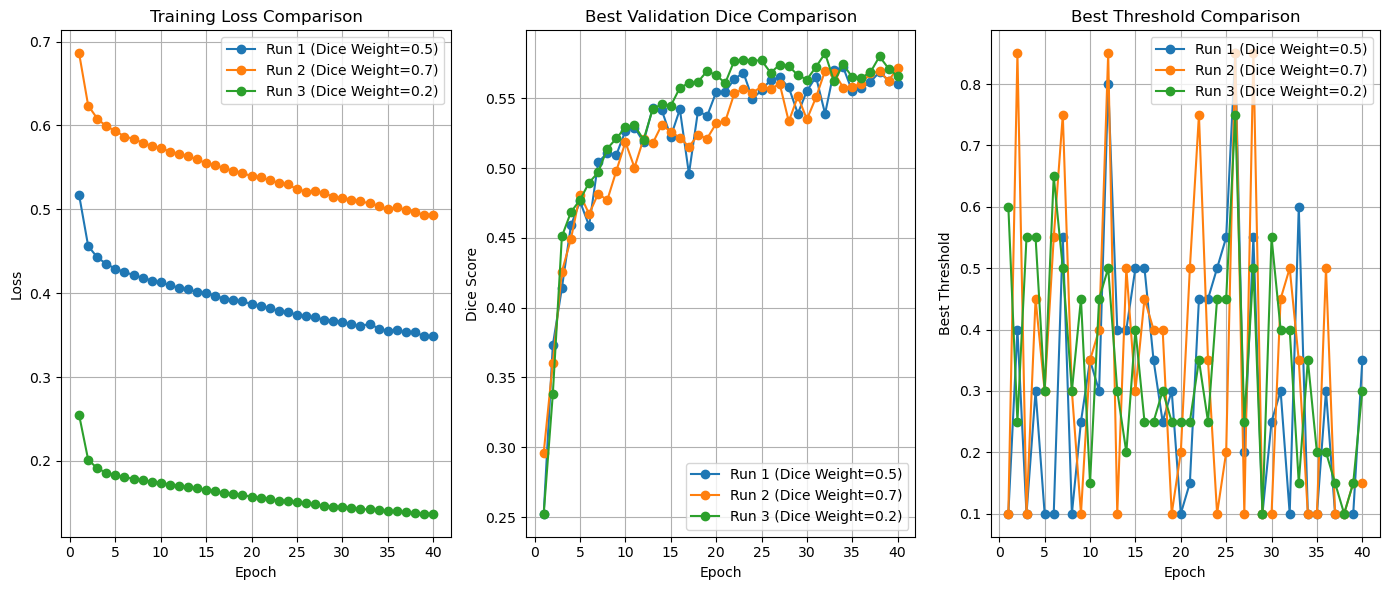

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import os


metrics_files = {
    "Run 1 (Dice Weight=0.5)": "Output/model01_dicebce0.5_loss/training_validation_metrics.csv",
    "Run 2 (Dice Weight=0.7)": "Output/model01_dicebce0.7_loss/training_validation_metrics.csv",
    "Run 3 (Dice Weight=0.2)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv"
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))


# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

  
# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



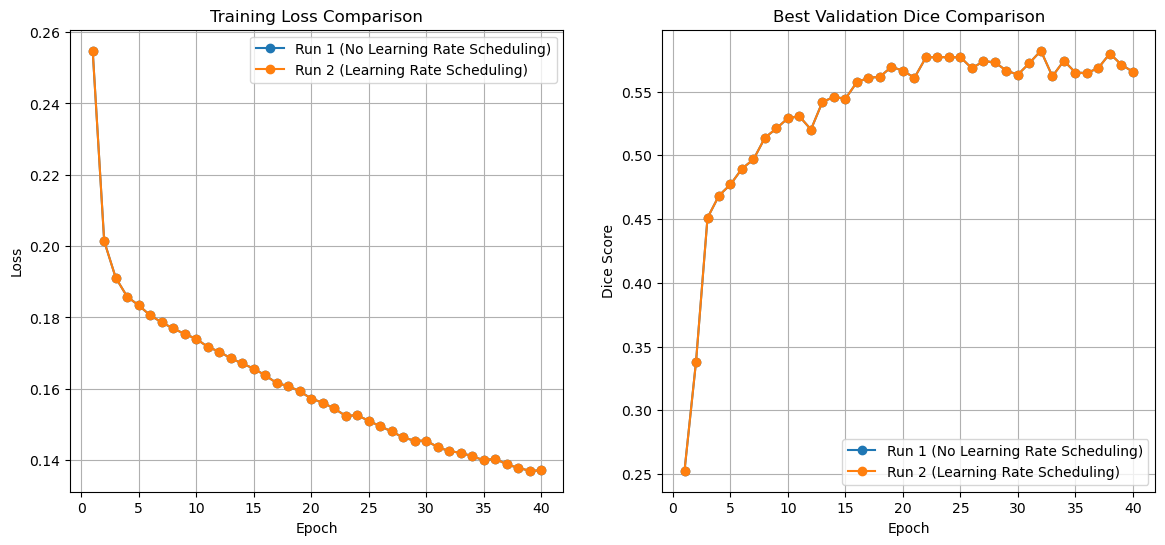

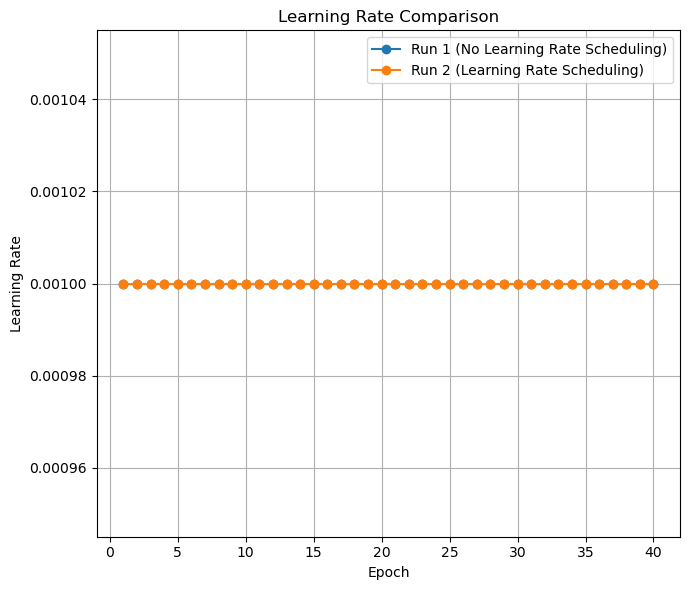

In [11]:
metrics_files = {
    "Run 1 (No Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss/training_validation_metrics.csv",
    "Run 2 (Learning Rate Scheduling)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
}    

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)  
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max")
    ).reset_index().head(40)

    if "Run 1" in label or "learning_rate" not in epoch_summary.columns:
        epoch_summary["learning_rate"] = 1e-3
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)

# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()

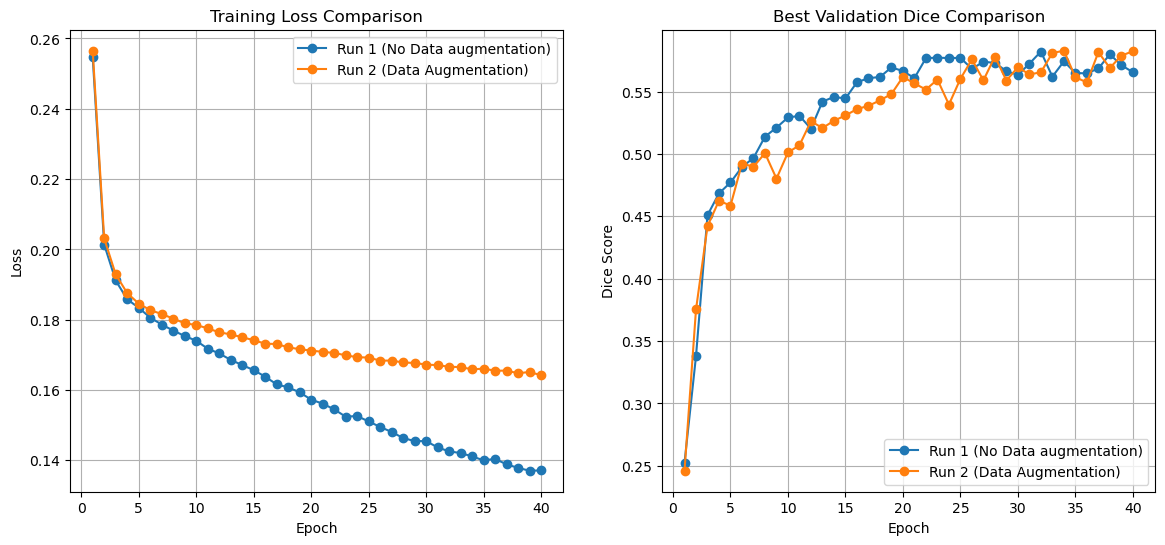

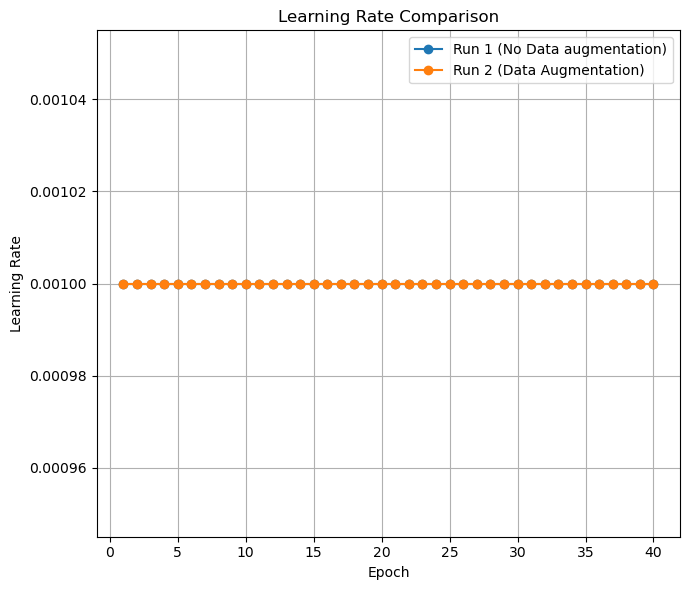

In [12]:
metrics_files = {
    "Run 1 (No Data augmentation)": "Output/model01_dicebce0.2_loss_scheduler/training_validation_metrics.csv",
    "Run 2 (Data Augmentation)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



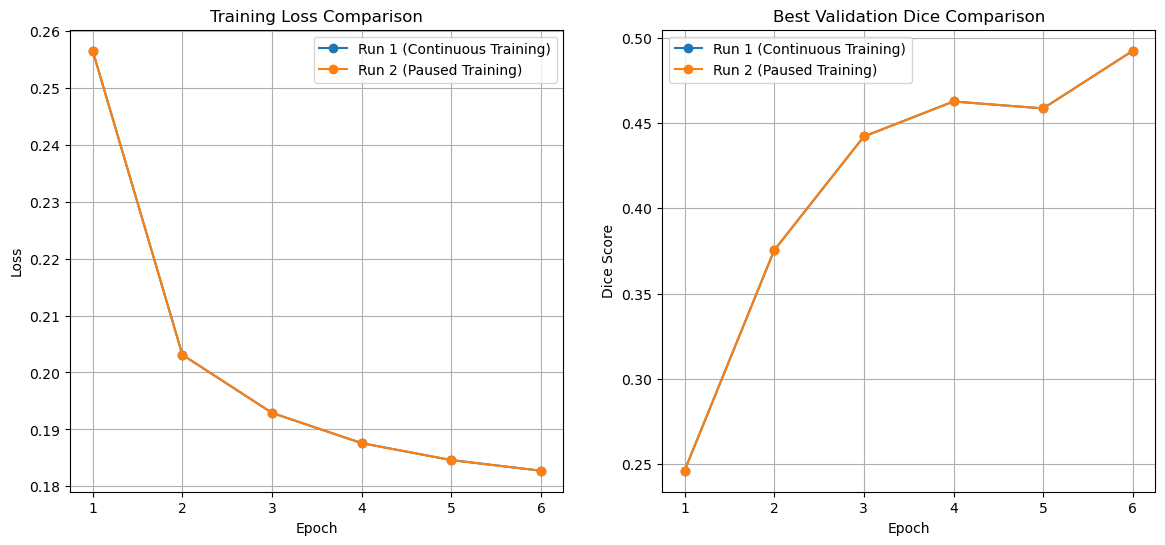

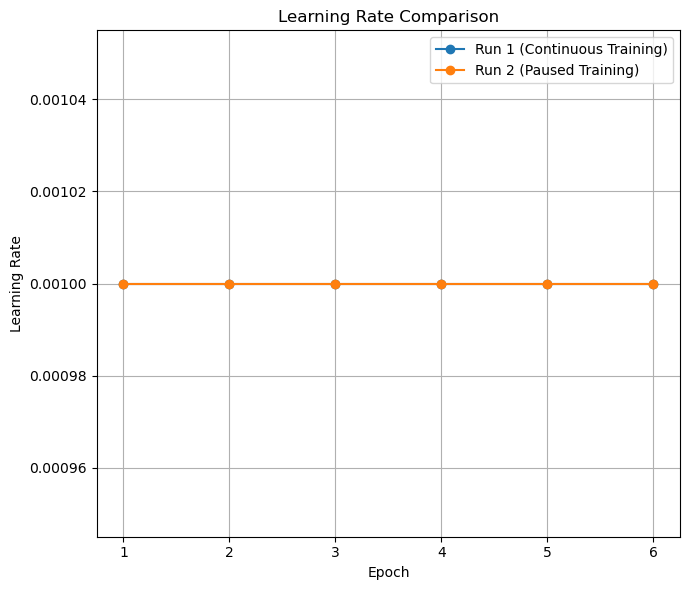

In [13]:
metrics_files = {
    "Run 1 (Continuous Training)": "Output/model01_continuity_test_full/training_validation_metrics.csv",
    "Run 2 (Paused Training)": "Output/model01_continuity_test_continued_max_6_from_3/training_validation_metrics.csv"
}

fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
fig2, ax3 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Learning Rate Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Learning Rate")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)
    
    # Group by epoch to handle the multiple threshold rows per epoch
    # We take the 'first' loss (since it's identical across thresholds) 
    # and the 'max' dice score achieved in that epoch
    epoch_summary = df.groupby("epoch").agg(
        train_loss=("avg_train_loss", "first"),
        best_dice=("dice", "max"),
        learning_rate=("learning_rate", "first")
    ).reset_index().head(6)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["best_dice"], marker='o', label=label)

    # Plot Learning Rate
    ax3.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
plt.tight_layout()
plt.show()



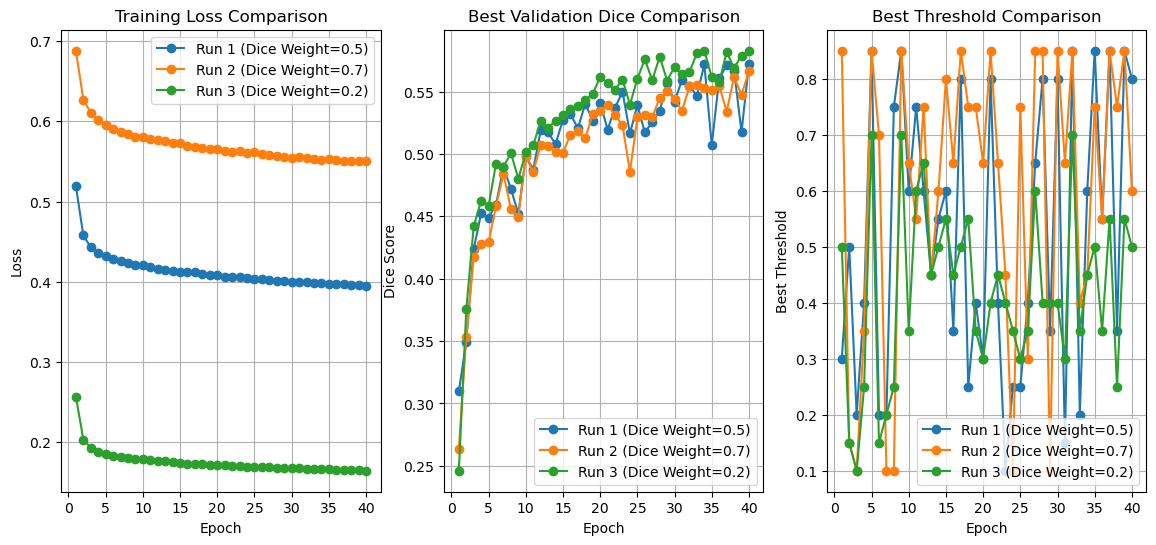

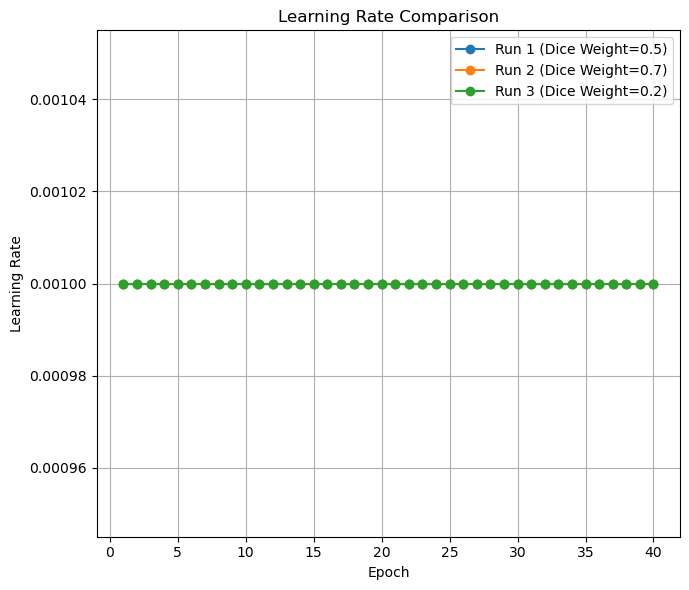

In [ ]:
metrics_files = {
    "Run 1 (Dice Weight=0.5)": "Output/model01_dicebce0.5_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 2 (Dice Weight=0.7)": "Output/model01_dicebce0.7_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 3 (Dice Weight=0.2)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv"
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



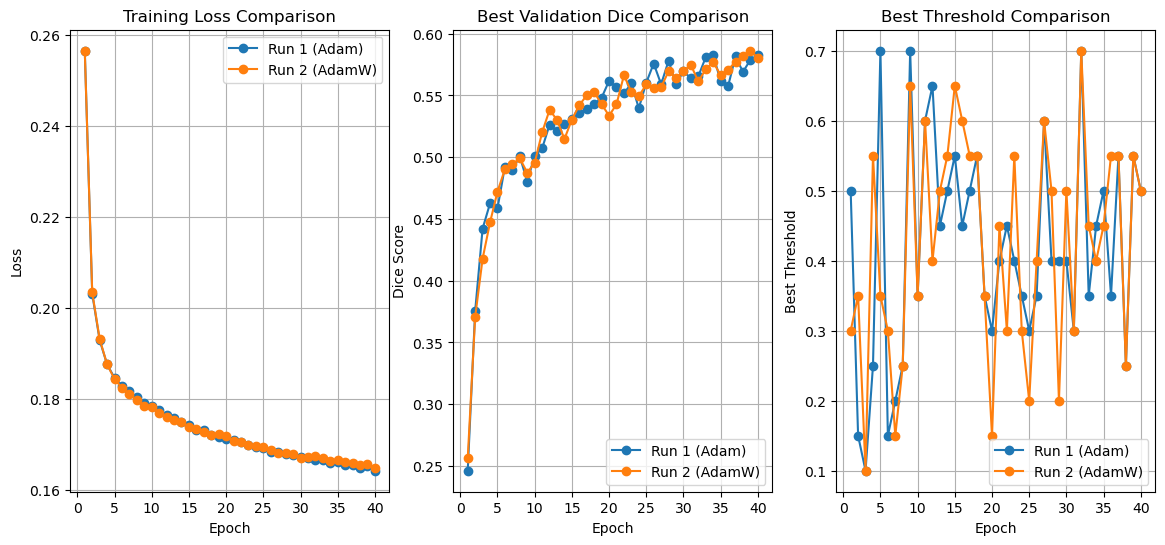

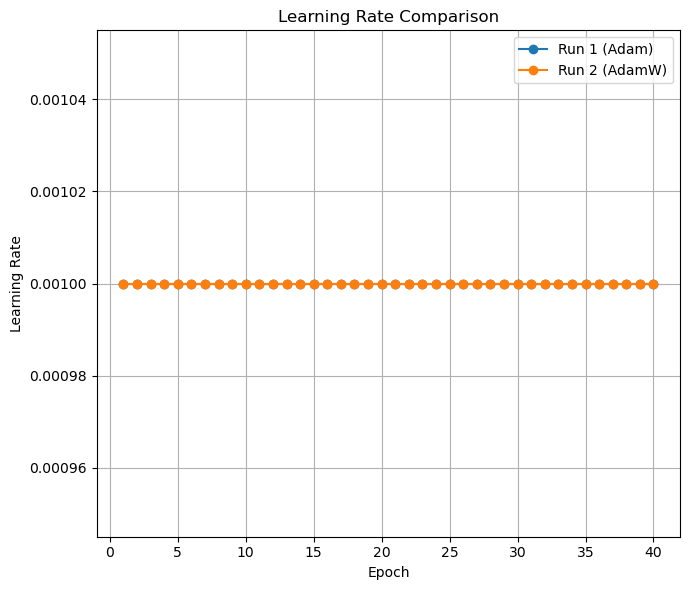

In [22]:
metrics_files = {
    "Run 1 (Adam)": "Output/model01_dicebce0.2_loss_scheduler_augmented/training_validation_metrics.csv",
    "Run 2 (AdamW)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw/training_validation_metrics.csv",
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



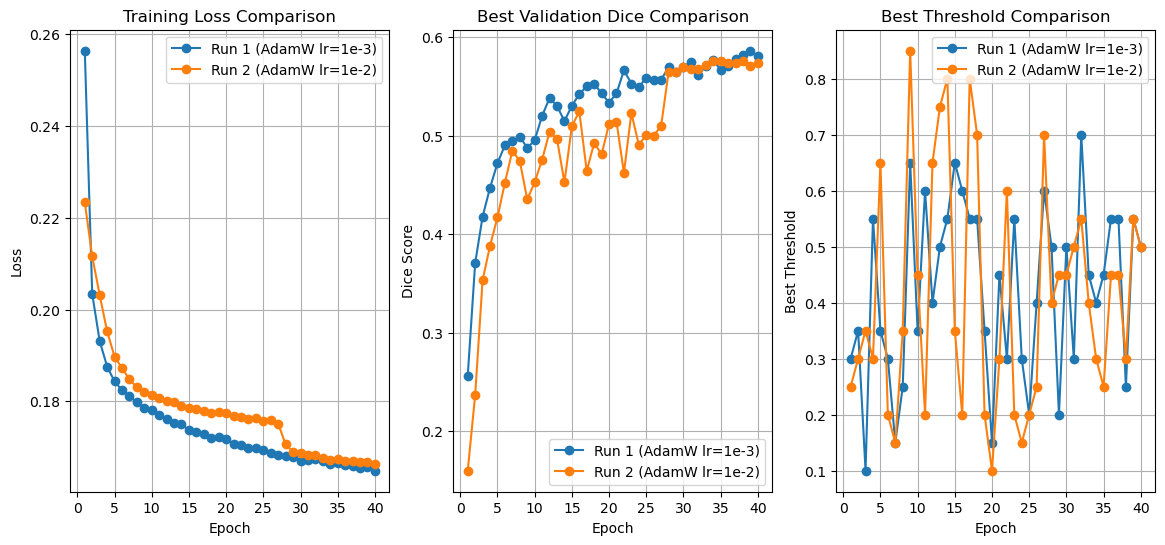

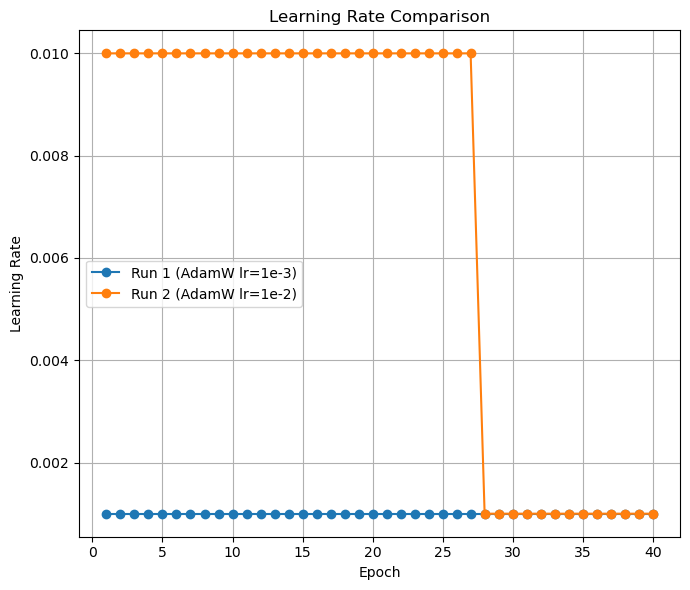

In [23]:
metrics_files = {
    "Run 1 (AdamW lr=1e-3)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw/training_validation_metrics.csv",
    "Run 2 (AdamW lr=1e-2)": "Output/model01_dicebce0.2_loss_scheduler_augmented_adamw_lr/training_validation_metrics.csv",
}

fig1, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 6))
fig2, ax4 = plt.subplots(figsize=(7, 6))

ax1.set_title("Training Loss Comparison")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

ax2.set_title("Best Validation Dice Comparison")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice Score")
ax2.grid(True)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))

ax3.set_title("Best Threshold Comparison")
ax3.set_xlabel("Epoch")
ax3.set_ylabel("Best Threshold")
ax3.grid(True)
ax3.xaxis.set_major_locator(MaxNLocator(integer=True))

ax4.set_title("Learning Rate Comparison")
ax4.set_xlabel("Epoch")
ax4.set_ylabel("Learning Rate")
ax4.grid(True)
ax4.xaxis.set_major_locator(MaxNLocator(integer=True))

# 3. Process and plot each file
for label, filepath in metrics_files.items():
    if not os.path.exists(filepath):
        print(f"Warning: File not found: {filepath}. Skipping '{label}'.")
        continue
        
    df = pd.read_csv(filepath)

    best_dice_idx = df.groupby("epoch")["dice"].idxmax()
    epoch_summary = df.loc[best_dice_idx].head(40)
    
    # Plot Loss
    ax1.plot(epoch_summary["epoch"], epoch_summary["avg_train_loss"], marker='o', label=label)
    
    # Plot Dice
    ax2.plot(epoch_summary["epoch"], epoch_summary["dice"], marker='o', label=label)
    
    # Plot Best Threshold
    ax3.plot(epoch_summary["epoch"], epoch_summary["threshold"], marker='o', label=label)

    # Plot Learning Rate
    ax4.plot(epoch_summary["epoch"], epoch_summary["learning_rate"], marker='o', label=label)


# 4. Add legends and show
ax1.legend()
ax2.legend()
ax3.legend()
ax4.legend()
plt.tight_layout()
plt.show()



In [25]:
results = []

for folder_name in os.listdir('Output'):
    
    metrics_file = os.path.join('Output', folder_name, "training_validation_metrics.csv")
        
    if os.path.exists(metrics_file):
            try:
                df = pd.read_csv(metrics_file)
                
                if 'dice' in df.columns:
                    best_idx = df['dice'].idxmax()
                    best_row = df.loc[best_idx]
                    results.append({
                        'Folder': folder_name,
                        'Best Dice': best_row['dice'],
                        'Epoch': int(best_row['epoch']),
                        'Threshold': best_row['threshold']
                    })
            except Exception as e:
                print(f"Error reading {metrics_file}: {e}")


results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='Best Dice', ascending=False).reset_index(drop=True)
print(results_df.to_string())

                                                  Folder  Best Dice  Epoch  Threshold
0      model01_dicebce0.2_loss_scheduler_augmented_adamw   0.586211     39       0.55
1            model01_dicebce0.2_loss_scheduler_augmented   0.582810     34       0.45
2                                model01_dicebce0.2_loss   0.582136     32       0.40
3                      model01_dicebce0.2_loss_scheduler   0.582136     32       0.40
4   model01_dicebce0.2_loss_scheduler_augmented_adamw_lr   0.576266     35       0.25
5            model01_dicebce0.5_loss_scheduler_augmented   0.572141     40       0.80
6                                model01_dicebce0.5_loss   0.572023     34       0.10
7                                model01_dicebce0.7_loss   0.571537     40       0.15
8            model01_dicebce0.7_loss_scheduler_augmented   0.566522     40       0.60
9         model01_continuity_test_continued_max_6_from_3   0.492383      6       0.15
10                          model01_continuity_test_fu

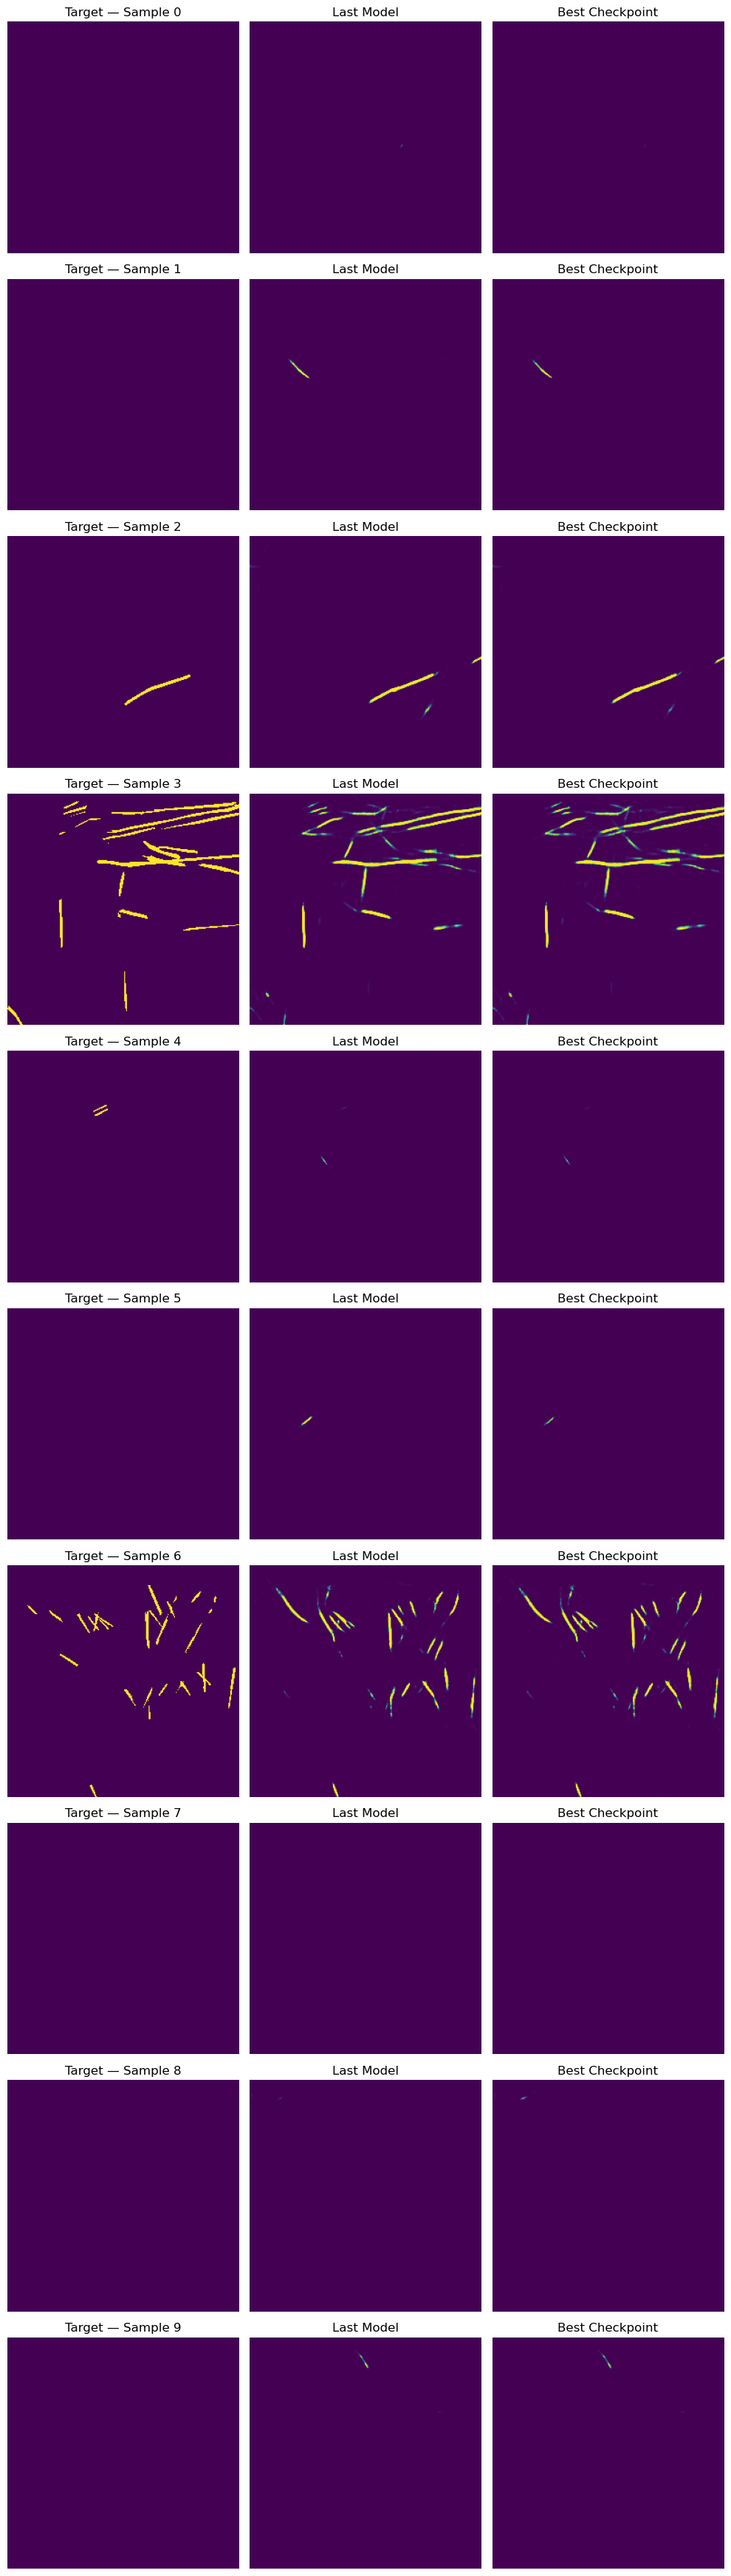

Unique values: [0. 1.]


In [ ]:
import Models
import torch
import glob
import h5py
import random
import numpy as np
from src.dataset import Dataset
from torch.utils.data import DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Data/ae4353-2026"

OUTPUT_BASE_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output"
SESSION_ID = "model01_dicebce0.2_loss_scheduler_augmented_adamw_more_epochs"
model = Models.model01.Contrail_CNN()

OUTPUT_PATH = os.path.join(OUTPUT_BASE_PATH, SESSION_ID)
train_files = sorted(glob.glob(f"{DATASET_PATH}/train_*.h5"))
VAL_SPLIT = 0.2
BATCH_SIZE = 8
NUM_WORKERS = 4
SEED = 2006
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)                     # seeds the GPU as well
torch.backends.cudnn.benchmark = False      # the same algorithms on every run
torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


total_train_images = sum([len(h5py.File(f, 'r')['bands']) for f in train_files])

val_size = int(total_train_images * VAL_SPLIT)
train_size = total_train_images - val_size

# Shuffle the indices of the training images
indices = torch.randperm(total_train_images, generator=torch.Generator().manual_seed(SEED)).tolist()
val_indices = indices[:val_size]
train_indices = indices[val_size:]

full_train_dataset = Dataset(train_files, is_test=False, do_augmentation=True, seed=SEED)
full_val_dataset = Dataset(train_files, is_test=False, do_augmentation=False, seed=SEED)
train_dataset = torch.utils.data.Subset(full_train_dataset, train_indices)
val_dataset = torch.utils.data.Subset(full_val_dataset, val_indices)

g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=g,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)


best_checkpoint_path = os.path.join(OUTPUT_PATH, "best_checkpoint.pth")
last_checkpoint_path = os.path.join(OUTPUT_PATH, "last_checkpoint.pth")
best_checkpoint = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
last_checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)


# Comparison of Last and Best Model Predictions
model.load_state_dict(last_checkpoint['model_state_dict'])

# Starting with the last model
model.eval()
model.to(device)

selected_indices = list(range(min(10, len(val_dataset))))
last_preds_samples = []
sample_images = []
sample_targets = []

with torch.no_grad():
    for idx in selected_indices:
        img, target_mask = val_dataset[idx]
        sample_images.append(img)
        sample_targets.append(target_mask.squeeze().numpy())
        
        pred = model(img.unsqueeze(0).to(device))
        last_preds_samples.append(torch.sigmoid(pred).squeeze().cpu().numpy())

# Best Model
model.load_state_dict(best_checkpoint['model_state_dict'])
model.eval() # Good practice to explicitly set eval again

best_preds_samples = []

with torch.no_grad():
    for img in sample_images:
        pred = model(img.unsqueeze(0).to(device))
        best_preds_samples.append(torch.sigmoid(pred).squeeze().cpu().numpy())

# Plot
n_samples = len(sample_images)
fig, axes = plt.subplots(n_samples, 3, figsize=(10, 3.5 * n_samples))
axes = np.atleast_2d(axes)

for row in range(n_samples):
    # Ground Truth
    axes[row, 0].imshow(sample_targets[row], cmap="viridis")
    axes[row, 0].set_title(f"Target — Sample {selected_indices[row]}")
    axes[row, 0].axis("off")

    # Last Model (Heatmap)
    axes[row, 1].imshow(last_preds_samples[row], cmap="viridis", vmin=0, vmax=1)
    axes[row, 1].set_title("Last Model")
    axes[row, 1].axis("off")

    # Best Model (Heatmap)
    axes[row, 2].imshow(best_preds_samples[row], cmap="viridis", vmin=0, vmax=1)
    axes[row, 2].set_title("Best Checkpoint")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_PATH, "prediction_examples_comparison.png"))
plt.show()
plt.close()